# Logistic Regression
---

## Experiment: visualize the logistic link and simulate binary responses.

Probability at x=0: 0.31
Probability at x=1: 0.6457
Probability-one-half boundary: 0.5714


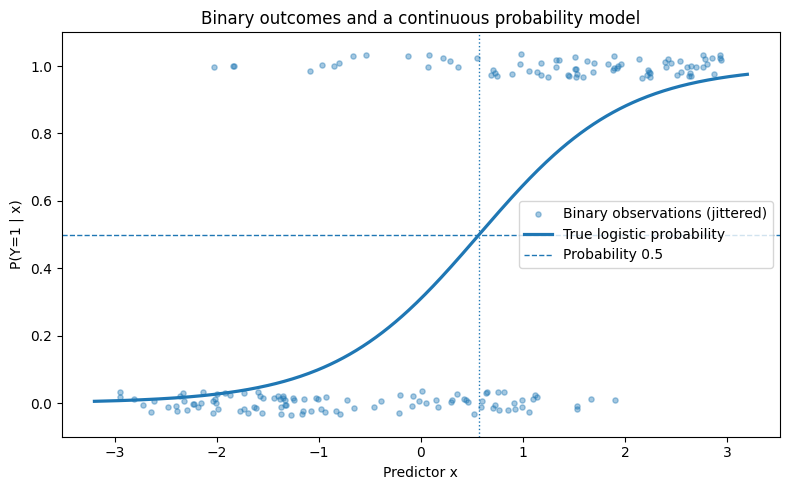

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit

rng = np.random.default_rng(133)
intercept, slope = -0.8, 1.4
x = rng.uniform(-3, 3, size=180)
p = expit(intercept + slope*x)
y = rng.binomial(n=1, p=p)

grid = np.linspace(-3.2, 3.2, 400)
probability = expit(intercept + slope*grid)
print("Probability at x=0:", round(expit(intercept), 4))
print("Probability at x=1:", round(expit(intercept + slope), 4))
print("Probability-one-half boundary:", round(-intercept/slope, 4))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y + rng.uniform(-0.035, 0.035, len(y)), s=14,
           alpha=0.40, label="Binary observations (jittered)")
ax.plot(grid, probability, linewidth=2.3, label="True logistic probability")
ax.axhline(0.5, linestyle="--", linewidth=1, label="Probability 0.5")
ax.axvline(-intercept/slope, linestyle=":", linewidth=1)
ax.set(xlabel="Predictor x", ylabel="P(Y=1 | x)", ylim=(-0.1, 1.1),
       title="Binary outcomes and a continuous probability model")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/logistic_sigmoid_probability.png", dpi=170,
            bbox_inches="tight")
plt.show()

## Experiment: fit the maximum-likelihood coefficients from first principles.

Numerical optimization: [-0.59795  1.02441]
statsmodels MLE:      [-0.59795  1.02441]
Optimizer message: Optimization terminated successfully.
Coefficient difference: [0. 0.]


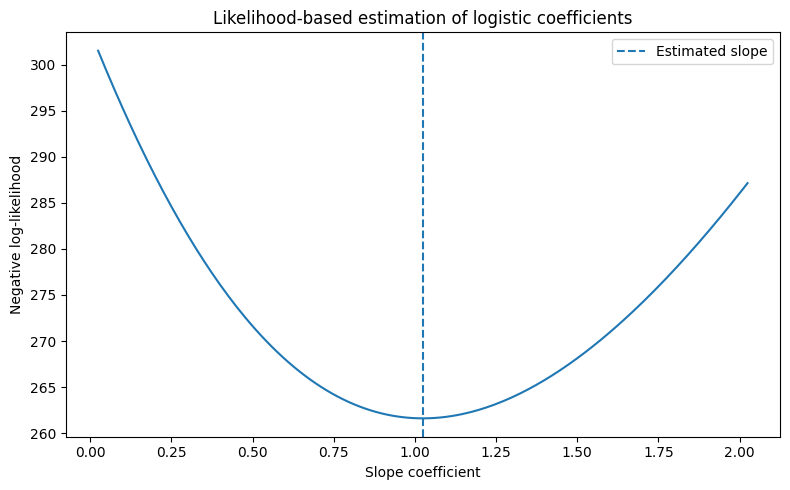

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import expit
from scipy.optimize import minimize

rng = np.random.default_rng(134)
x = rng.normal(size=450)
y = rng.binomial(1, expit(-0.6 + 1.1*x))
X = np.column_stack((np.ones_like(x), x))

def negative_log_likelihood(beta):
    eta = X @ beta
    return np.logaddexp(0, eta).sum() - y @ eta

def gradient(beta):
    return X.T @ (expit(X @ beta) - y)

fit_manual = minimize(negative_log_likelihood, x0=[0.0, 0.0],
                      jac=gradient, method="BFGS",
                      options={"gtol": 1e-7})
fit_statsmodels = sm.Logit(y, X).fit(disp=False)
print("Numerical optimization:", np.round(fit_manual.x, 5))
print("statsmodels MLE:     ", np.round(fit_statsmodels.params, 5))
print("Optimizer message:", fit_manual.message)
print("Coefficient difference:",
      np.round(fit_manual.x - fit_statsmodels.params, 6))

# Slice the negative log-likelihood in the slope, holding the intercept fixed.
beta0_hat, beta1_hat = fit_statsmodels.params
slopes = np.linspace(beta1_hat - 1, beta1_hat + 1, 240)
losses = [negative_log_likelihood([beta0_hat, b]) for b in slopes]
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(slopes, losses)
ax.axvline(beta1_hat, linestyle="--", label="Estimated slope")
ax.set(xlabel="Slope coefficient", ylabel="Negative log-likelihood",
       title="Likelihood-based estimation of logistic coefficients")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/logistic_likelihood_profile.png", dpi=170,
            bbox_inches="tight")
plt.show()

## Experiment: interpret estimated odds ratios and confidence intervals.

In [3]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.special import expit

rng = np.random.default_rng(135)
n = 700
x = rng.normal(size=n)
z = rng.binomial(1, 0.45, size=n)
p = expit(-1.1 + 0.75*x + 0.9*z)
y = rng.binomial(1, p)

X = sm.add_constant(pd.DataFrame({"x": x, "z": z}))
fit = sm.Logit(y, X).fit(disp=False)
interval = fit.conf_int(alpha=0.05)
summary = pd.DataFrame({
    "log_odds_coef": fit.params,
    "odds_ratio": np.exp(fit.params),
    "OR_lower_95": np.exp(interval.iloc[:, 0]),
    "OR_upper_95": np.exp(interval.iloc[:, 1]),
    "Wald_p_value": fit.pvalues
})
print(summary.round(4))

new = pd.DataFrame({"const": [1, 1], "x": [0.5, 0.5], "z": [0, 1]})
probabilities = np.asarray(fit.predict(new))
print("Predicted probabilities at x=0.5, z=0 vs 1:",
      np.round(probabilities, 4))
print("Probability difference:", round(probabilities[1] - probabilities[0], 4))

       log_odds_coef  odds_ratio  OR_lower_95  OR_upper_95  Wald_p_value
const        -1.0922      0.3355       0.2642       0.4260           0.0
x             0.6638      1.9422       1.6247       2.3217           0.0
z             0.8098      2.2475       1.6133       3.1310           0.0
Predicted probabilities at x=0.5, z=0 vs 1: [0.3186 0.5124]
Probability difference: 0.1938


## Experiment: compare Wald and likelihood-ratio inference for a coefficient.

In [6]:
import numpy as np
import statsmodels.api as sm
from scipy.special import expit
from scipy.stats import chi2, norm

rng = np.random.default_rng(136)
x = rng.normal(size=600)
z = rng.normal(size=600)
y = rng.binomial(1, expit(-0.5 + 0.7*x + 0.4*z))
X_full = sm.add_constant(np.column_stack((x, z)))
X_reduced = sm.add_constant(x)
full = sm.Logit(y, X_full).fit(disp=False)
reduced = sm.Logit(y, X_reduced).fit(disp=False)

# H0: the coefficient of z is zero.
beta_z, se_z = full.params[2], full.bse[2]
z_value = beta_z / se_z
wald_p = 2*norm.sf(abs(z_value))
LR = 2*(full.llf - reduced.llf)
lr_p = chi2.sf(LR, df=1)
ci = full.conf_int()[2]
print(f"Wald z={z_value:.4f}, p={wald_p:.3g}")
print(f"LR statistic={LR:.4f}, p={lr_p:.3g}")
print("95% confidence interval for beta_z:", np.round(ci, 4))
print("95% confidence interval for its OR:", np.round(np.exp(ci), 4))

Wald z=4.9796, p=6.37e-07
LR statistic=26.3972, p=2.78e-07
95% confidence interval for beta_z: [0.2964 0.6812]
95% confidence interval for its OR: [1.345  1.9763]


## Experiment: demonstrate separation and finite regularized fits.

C=0.1: regularized slope=1.034
C=1.0: regularized slope=2.386
C=100.0: regularized slope=9.691


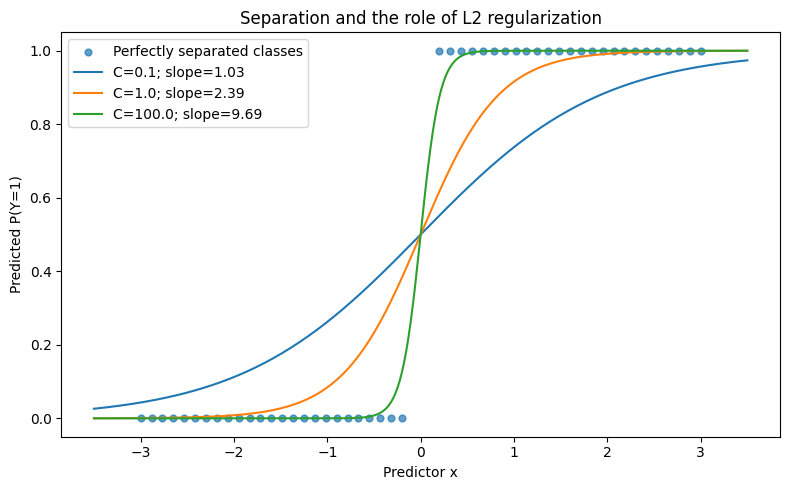

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

x = np.r_[np.linspace(-3, -0.2, 25), np.linspace(0.2, 3, 25)]
y = (x > 0).astype(int)
grid = np.linspace(-3.5, 3.5, 300)[:, None]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, s=24, alpha=0.7, label="Perfectly separated classes")
for strength in (0.1, 1.0, 100.0):
    clf = LogisticRegression(C=strength, max_iter=1500)
    clf.fit(x[:, None], y)
    ax.plot(grid[:, 0], clf.predict_proba(grid)[:, 1],
            label=f"C={strength}; slope={clf.coef_[0, 0]:.2f}")
    print(f"C={strength}: regularized slope={clf.coef_[0, 0]:.3f}")
ax.set(xlabel="Predictor x", ylabel="Predicted P(Y=1)",
       title="Separation and the role of L2 regularization")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/logistic_separation.png", dpi=170, bbox_inches="tight")
plt.show()

##  Experiment: fit a leakage-safe binary classifier and evaluate held-out predictions.

Positive class: malignant
Confusion matrix [[TN, FP], [FN, TP]]:
[[90  0]
 [ 3 50]]
Accuracy: 0.979
Precision: 1.0
Recall: 0.9434
ROC AUC: 0.9992
Average precision: 0.9986
Log loss: 0.05


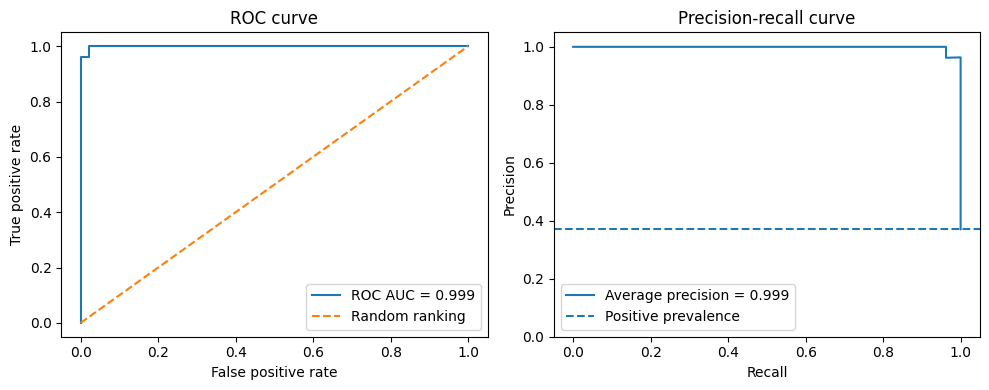

In [11]:
import numpy as np
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, log_loss,
                             roc_curve, precision_recall_curve)

# A bundled educational dataset; not a validated clinical diagnostic tool.
dataset = load_breast_cancer()
X = dataset.data
# Original label 0 = malignant, 1 = benign. Choose malignant as class 1.
y = (dataset.target == 0).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=138, stratify=y)

model = make_pipeline(StandardScaler(),
                      LogisticRegression(C=1.0, max_iter=3000))
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.5).astype(int)
print("Positive class: malignant")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, pred))
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("Recall:", round(recall_score(y_test, pred), 4))
print("ROC AUC:", round(roc_auc_score(y_test, prob), 4))
print("Average precision:", round(average_precision_score(y_test, prob), 4))
print("Log loss:", round(log_loss(y_test, prob), 4))

fpr, tpr, _ = roc_curve(y_test, prob)
precision, recall, _ = precision_recall_curve(y_test, prob)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(fpr, tpr, label=f"ROC AUC = {roc_auc_score(y_test, prob):.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", label="Random ranking")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate",
            title="ROC curve")
axes[0].legend()
axes[1].plot(recall, precision,
             label=f"Average precision = {average_precision_score(y_test, prob):.3f}")
axes[1].axhline(np.mean(y_test), linestyle="--", label="Positive prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision", ylim=(0, 1.05),
            title="Precision-recall curve")
axes[1].legend()
fig.tight_layout()
fig.savefig("../../images/logistic_roc_pr.png", dpi=170, bbox_inches="tight")
plt.show()

##  Experiment: choose a decision threshold on validation data, then evaluate once on test data.

Threshold selected from validation: 0.18
Test precision: 0.9286
Test recall: 0.9811
Test confusion matrix:
 [[86  4]
 [ 1 52]]


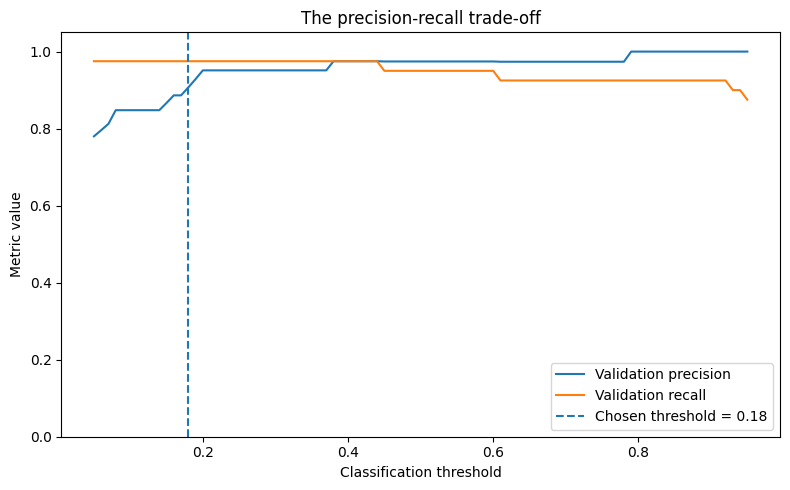

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score,
                             confusion_matrix, precision_recall_curve)

source = load_breast_cancer()
X, y = source.data, (source.target == 0).astype(int)
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=139)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25,
    stratify=y_trainval, random_state=139)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
model.fit(X_train, y_train)
val_prob = model.predict_proba(X_val)[:, 1]

# Choose the threshold on validation data only. For this demonstration,
# maximize recall subject to validation precision >= 0.90.
thresholds = np.linspace(0.05, 0.95, 91)
val_precision = np.array([precision_score(
    y_val, val_prob >= t, zero_division=0) for t in thresholds])
val_recall = np.array([recall_score(
    y_val, val_prob >= t, zero_division=0) for t in thresholds])
valid = np.flatnonzero(val_precision >= 0.90)
if not len(valid):
    raise ValueError("No candidate threshold meets the validation constraint")
chosen = valid[np.argmax(val_recall[valid])]
t_star = float(thresholds[chosen])

# A single final report on untouched test data.
test_prob = model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= t_star).astype(int)
print("Threshold selected from validation:", t_star)
print("Test precision:", round(precision_score(y_test, test_pred), 4))
print("Test recall:", round(recall_score(y_test, test_pred), 4))
print("Test confusion matrix:\n", confusion_matrix(y_test, test_pred))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, val_precision, label="Validation precision")
ax.plot(thresholds, val_recall, label="Validation recall")
ax.axvline(t_star, linestyle="--", label=f"Chosen threshold = {t_star:.2f}")
ax.set(xlabel="Classification threshold", ylabel="Metric value",
       ylim=(0, 1.05), title="The precision-recall trade-off")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/logistic_threshold_tradeoff.png", dpi=170,
            bbox_inches="tight")
plt.show()

## Experiment: compare calibrated and overconfident probabilities.

Correct conditional probabilities
  Brier: 0.1948 log loss: 0.5727 ROC AUC: 0.7423
Overconfident probabilities
  Brier: 0.2076 log loss: 0.6371 ROC AUC: 0.7423


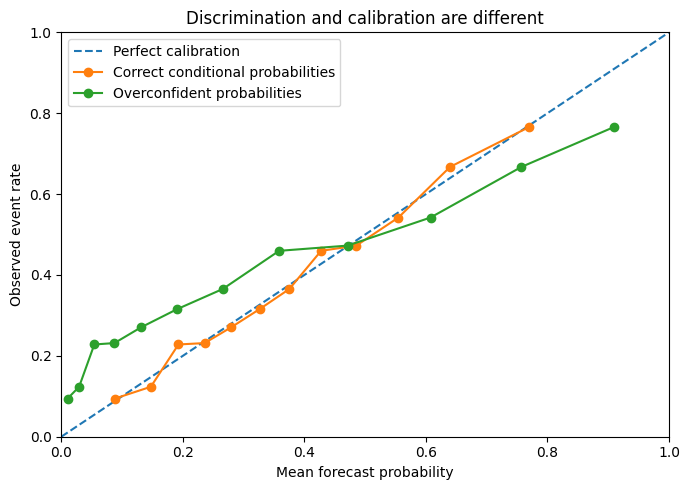

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit, logit
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

rng = np.random.default_rng(140)
score = rng.normal(size=7000)
true_prob = expit(-0.6 + score)
y = rng.binomial(1, true_prob)

# A thought experiment: one model knows the true conditional probability;
# the other reports an overly extreme score, preserving all ranks.
candidates = {
    "Correct conditional probabilities": true_prob,
    "Overconfident probabilities": expit(2*logit(true_prob))
}
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
for label, prob in candidates.items():
    observed, forecast = calibration_curve(y, prob, n_bins=12,
                                            strategy="quantile")
    ax.plot(forecast, observed, marker="o", label=label)
    print(label)
    print("  Brier:", round(brier_score_loss(y, prob), 4),
          "log loss:", round(log_loss(y, prob), 4),
          "ROC AUC:", round(roc_auc_score(y, prob), 4))
ax.set(xlabel="Mean forecast probability", ylabel="Observed event rate",
       xlim=(0, 1), ylim=(0, 1),
       title="Discrimination and calibration are different")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/logistic_calibration.png", dpi=170,
            bbox_inches="tight")
plt.show()

## Experiment: compare ROC AUC, average precision, and baseline accuracy for rare events. 

In [15]:
import numpy as np
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             average_precision_score, roc_auc_score,
                             precision_score, recall_score)

rng = np.random.default_rng(141)
X = rng.normal(size=(3500, 3))
true_prob = expit(-3.5 + 1.0*X[:, 0] - 0.5*X[:, 1])
y = rng.binomial(1, true_prob)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=141)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
model.fit(X_train, y_train)
pred_prob = model.predict_proba(X_test)[:, 1]
pred_label = (pred_prob >= 0.5).astype(int)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_label = baseline.predict(X_test)

print("Positive prevalence:", round(np.mean(y_test), 4))
print("Always-negative baseline accuracy:",
      round(accuracy_score(y_test, base_label), 4))
print("Logistic accuracy:", round(accuracy_score(y_test, pred_label), 4))
print("Logistic balanced accuracy:",
      round(balanced_accuracy_score(y_test, pred_label), 4))
print("Logistic recall at 0.5:", round(recall_score(y_test, pred_label), 4))
print("ROC AUC:", round(roc_auc_score(y_test, pred_prob), 4))
print("Average precision:",
      round(average_precision_score(y_test, pred_prob), 4))
print("PR baseline (prevalence):", round(np.mean(y_test), 4))

Positive prevalence: 0.0495
Always-negative baseline accuracy: 0.9505
Logistic accuracy: 0.9505
Logistic balanced accuracy: 0.5182
Logistic recall at 0.5: 0.0385
ROC AUC: 0.8178
Average precision: 0.2184
PR baseline (prevalence): 0.0495


## Experiment: apply logistic regression to a constructed exam-score outcome.

Data source: SOGA-Py students (external data)
Training-defined score2 threshold: 71.0
Test ROC AUC: 0.9378
Test Brier score: 0.1006


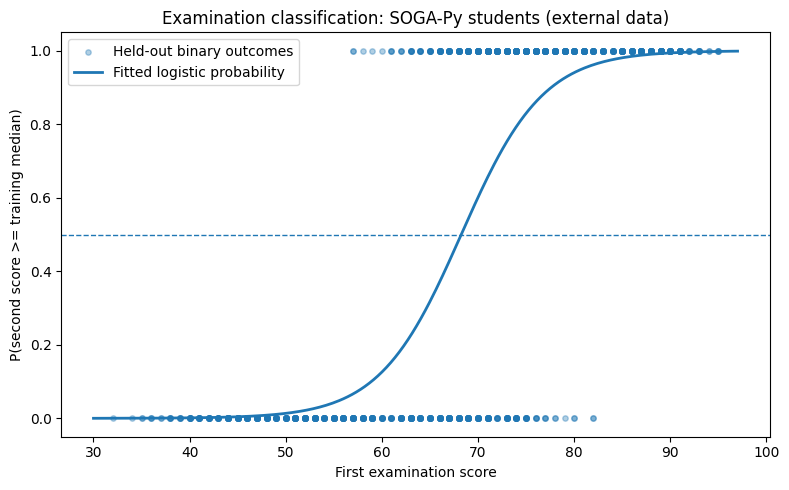

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss

url = "https://userpage.fu-berlin.de/soga/data/raw-data/students.csv"
try:
    students = pd.read_csv(url)
    data_source = "SOGA-Py students (external data)"
except Exception as error:
    print("Download unavailable; using simulated data:", type(error).__name__)
    rng = np.random.default_rng(142)
    score1 = rng.normal(70, 11, 550)
    score2 = 24 + 0.67*score1 + rng.normal(0, 9, len(score1))
    students = pd.DataFrame({"score1": score1, "score2": score2})
    data_source = "SIMULATED DEMONSTRATION DATA"

clean = students[["score1", "score2"]].apply(
    pd.to_numeric, errors="coerce").dropna()
if len(clean) < 60:
    raise ValueError("At least 60 complete examination-score pairs are needed")
X = clean[["score1"]].to_numpy()
raw_score2 = clean["score2"].to_numpy()
X_train, X_test, s2_train, s2_test = train_test_split(
    X, raw_score2, test_size=0.25, random_state=142)
threshold = float(np.median(s2_train))
y_train = (s2_train >= threshold).astype(int)
y_test = (s2_test >= threshold).astype(int)
if len(np.unique(y_test)) != 2:
    raise ValueError("Need both outcome classes in the test sample")

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
model.fit(X_train, y_train)
prob = model.predict_proba(X_test)[:, 1]
print("Data source:", data_source)
print("Training-defined score2 threshold:", round(threshold, 3))
print("Test ROC AUC:", round(roc_auc_score(y_test, prob), 4))
print("Test Brier score:", round(brier_score_loss(y_test, prob), 4))

x_grid = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X_test[:, 0], y_test, s=15, alpha=0.35,
           label="Held-out binary outcomes")
ax.plot(x_grid[:, 0], model.predict_proba(x_grid)[:, 1],
        linewidth=2, label="Fitted logistic probability")
ax.axhline(0.5, linestyle="--", linewidth=1)
ax.set(xlabel="First examination score", ylabel="P(second score >= training median)",
       ylim=(-0.05, 1.05), title=f"Examination classification: {data_source}")
ax.legend()
fig.tight_layout()
fig.savefig("../../images/logistic_student_exam_outcome.png", dpi=170,
            bbox_inches="tight")
plt.show()